# The density of states without bands: the kernel polynomial method

How many states does a crystal have at energy $E$? The normal way to answer is to
compute the bands and count them. This needs every band in the energy window, and
the cost of the bands grows with the square of their number. The kernel polynomial
method (KPM) answers without computing any band. It expands the delta function
$\delta(E - H)$ in Chebyshev polynomials of the Hamiltonian, and it takes the trace
with a few random vectors. The cost is set by the broadening and by the cutoff, and
not by the number of bands.

Here we compute the DOS of silicon this way. We get 8.23 $\pm$ 0.25 states below the
gap, where the exact number is 8, the four valence bands with their spin. The DOS
agrees with the one from the bands within its noise. Then we look at the DOS of the
whole plane-wave basis, up to the cutoff, which a band calculation cannot give.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from defuqumat import Calculator

si = Calculator.from_keywords(
    lattice='fcc', a=5.43, atoms=[('Si', (0, 0, 0)), ('Si', (0.25, 0.25, 0.25))],
    pseudos={'Si': 'Si.pz-vbc.UPF'}, pseudo_dir='../tests/data/pseudo',
    ecut=163.3, kmesh=(4, 4, 4))
scf = si.get_scf()
kpm = si.get_kpm_dos(broadening=0.01, n_random=16, emax=scf.homo + 0.6)
print(f'{kpm.n_moments} moments, interval {kpm.centre - kpm.half_width:.2f} to {kpm.centre + kpm.half_width:.2f} Ry')

1212 moments, interval -0.66 to 11.81 Ry


## What is computed

The DOS is a trace, $D(E) = \sum_{\mathbf k} w_{\mathbf k}\,{\rm Tr}\,\delta(E - H_{\mathbf k})$,
taken in the plane-wave basis. We first rescale the Hamiltonian,
$H' = (H - c)/s$, so that its whole spectrum is inside $[-1, 1]$. Then

$$D(E) = \frac{1}{\pi s\sqrt{1-x^2}}\Big[g_0\mu_0 + 2\sum_{n\ge1} g_n\,\mu_n\,T_n(x)\Big],
\qquad \mu_n = \sum_{\mathbf k} w_{\mathbf k}\,{\rm Tr}\,T_n(H'_{\mathbf k}),$$

with $x = (E - c)/s$. The $T_n$ are the Chebyshev polynomials, and they obey
$T_{n+1}(H') = 2H'T_n(H') - T_{n-1}(H')$. So each moment $\mu_n$ costs one
application of $H$ to a vector, and nothing is diagonalized. The trace is the
average of $\langle r|T_n(H')|r\rangle$ over random vectors $|r\rangle$, so the DOS
has a statistical error, which falls as one over the square root of their number.
The $g_n$ are the Jackson kernel. They make the truncated series of a delta function
a positive peak, close to a Gaussian, and they set the broadening.

In a plane-wave basis the top of the spectrum is set by the cutoff, here about
12 Ry. So the interval is wide, and we need about a thousand moments for a
broadening of 0.01 Ry. Below we count the states up to the gap, and we compute the
same DOS from 12 bands.

In [2]:
gap = scf.homo + 0.02
print(f'states below the gap: {kpm.count_at(gap):.3f} +- {kpm.count_error_at(gap):.3f}')
dos = si.get_dos(nbnd=12, scheme='gaussian', degauss=kpm.broadening / np.sqrt(np.log(2)),
                 emin=kpm.energies[0], emax=kpm.energies[-1], delta_e=0.002)

states below the gap: 8.232 +- 0.252


The count is 8 within its error. On the left of the figure we compare the two
DOS near the gap. On the right we use the same moments over the whole interval, up
to the cutoff, cut to 200 moments, which is a broadening of about 1 eV.

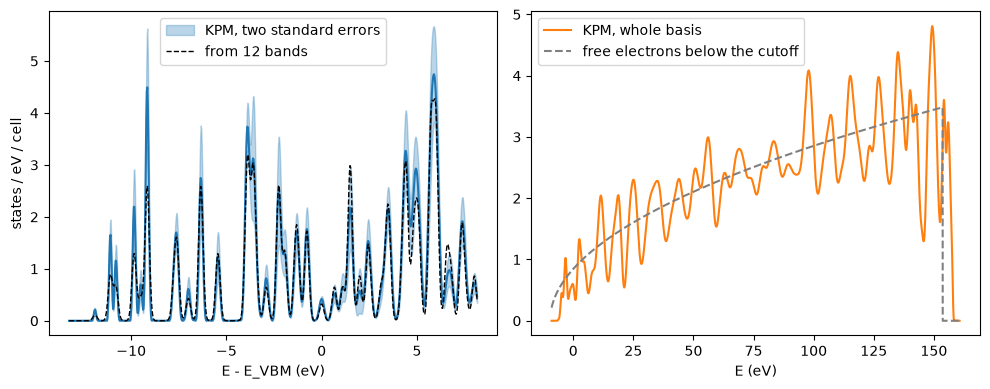

In [3]:
whole = kpm.reconstructed(energies=np.linspace(kpm.centre - kpm.half_width, kpm.centre + kpm.half_width, 3000), n_moments=200)
volume, v0, ecut = float(si.system.cell.volume), float(np.mean(scf.potential)), si.system.ecutwfc
e, ev = whole.energies, 13.6057
free = np.where((e > v0) & (e < v0 + ecut), volume * np.sqrt(np.clip(e - v0, 0, None)) / (2 * np.pi**2), 0)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
x = (kpm.energies - scf.homo) * ev
left.fill_between(x, (kpm.dos - 2 * kpm.dos_error) / ev, (kpm.dos + 2 * kpm.dos_error) / ev,
                  color='C0', alpha=0.3, label='KPM, two standard errors')
left.plot(x, kpm.dos / ev, color='C0')
left.plot((dos.energies - scf.homo) * ev, dos.dos / ev, color='k', ls='--', lw=1, label='from 12 bands')
left.set_xlabel('E - E_VBM (eV)'); left.set_ylabel('states / eV / cell'); left.legend()
right.plot(e * ev, whole.dos / ev, color='C1', label='KPM, whole basis')
right.plot(e * ev, free / ev, color='gray', ls='--', label='free electrons below the cutoff')
right.set_xlabel('E (eV)'); right.legend()
plt.tight_layout()

On the left, the two curves agree within the shaded band of two standard errors.
The many sharp peaks come from the $4\times4\times4$ mesh, which has only eight
k-points in the irreducible wedge.

On the right is the DOS of every state of the basis. Far above the gap the bands
are almost free electrons, and the DOS follows the free-electron
$D(E) = \Omega\sqrt{E - V_0}/(2\pi^2)$ (in Ry units, with the spin), with $V_0$ the
average potential. It stops at $V_0 + E_{\rm cut}$, because the basis has no plane
wave above the cutoff. A band calculation would need about 180 bands per k-point
to draw this curve.

The moments are kept on the result, so another broadening needs no new
calculation. Fewer moments give a wider peak:

In [4]:
for n in (kpm.n_moments, 400, 100):
    coarse = kpm.reconstructed(n_moments=n)
    print(f'{n:5d} moments: broadening {coarse.broadening * ev:.3f} eV, peak {coarse.dos.max() / ev:.2f} states/eV')

 1212 moments: broadening 0.136 eV, peak 4.74 states/eV
  400 moments: broadening 0.413 eV, peak 2.48 states/eV


  100 moments: broadening 1.668 eV, peak 1.55 states/eV


## When to use it

For this two-atom cell the bands are cheaper. The KPM cost does not depend on the
number of bands, so the method wins for large cells. We measured it on silicon
supercells with one k-point, at a broadening of 0.01 Ry, on one core. With 128
atoms the KPM DOS takes 44 s with eight random vectors, and its error is 8% of the
DOS. The same DOS from 321 bands takes 275 s. With 16 atoms the bands are faster.
The KPM also gives the empty states up to the cutoff at no extra cost.

The checks of these numbers are in `tests/unit/test_kpm.py`: the moments of the
whole basis against the eigenvalues of the dense Hamiltonian, the error against the
number of random vectors, the count in the gap, and the DOS against the bands.